In [3]:
from functions_py import *
import matplotlib.pyplot as plt
import matplotlib as mpl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy.ma as ma

In [4]:
plt.rcParams.update({
    "image.origin": "lower",
    "image.aspect": 1,
    #"text.usetex": True,
    "grid.alpha": .5,
    "axes.linewidth":2,
    "lines.linewidth" : 1,
    "font.size":    15.0,
    "xaxis.labellocation": 'right',  # alignment of the xaxis label: {left, right, center}
    "yaxis.labellocation": 'top',  # alignment of the yaxis label: {bottom, top, center}
    "xtick.top":           True ,  # draw ticks on the top side
    "xtick.major.size":    8    ,# major tick size in points
    "xtick.minor.size":    4      ,# minor tick size in points
    "xtick.direction":     'in',
    "xtick.minor.visible": True,
    "ytick.right":           True ,  # draw ticks on the top side
    "ytick.major.size":    8    ,# major tick size in points
    "ytick.minor.size":    4      ,# minor tick size in points
    "ytick.direction":     'in',
    "ytick.minor.visible": True,
    "ytick.major.width":   2   , # major tick width in points
    "ytick.minor.width":   1 ,
    "xtick.major.width":   2   , # major tick width in points
    "xtick.minor.width":   1 ,
    "legend.framealpha": 0 ,
    "legend.loc": 'best',

})

# MIT images

## Raw Image

Filename: /home/oem/datosFits/Data_2023/spuriousCharge/Microchip/01NOV23/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_71.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     165   (700, 400)   float32   
  1                1 ImageHDU       164   (700, 400)   float32   
  2                1 ImageHDU       164   (700, 400)   float32   
  3                1 ImageHDU       164   (700, 400)   float32   
None
----------------


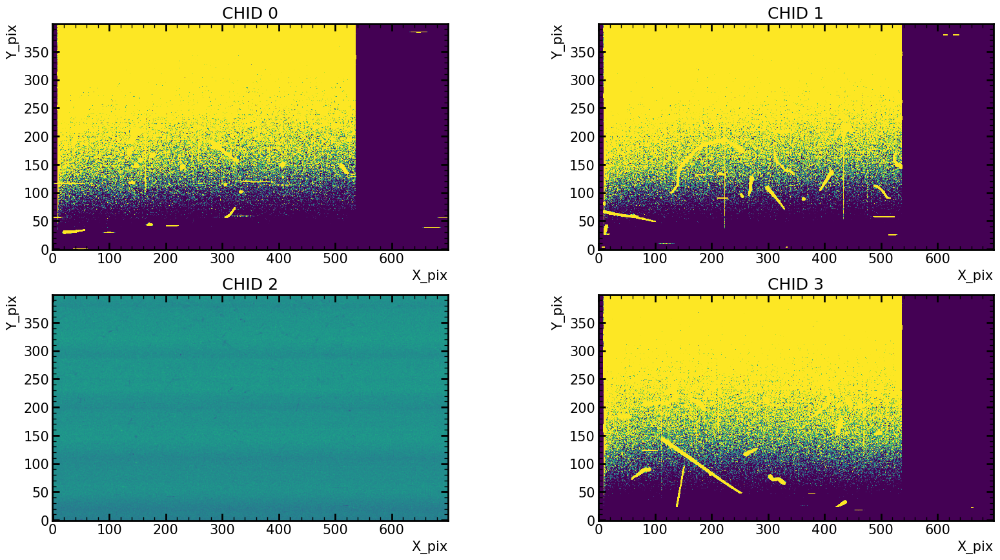

In [80]:
path='/home/oem/datosFits/Data_2023/spuriousCharge/Microchip/01NOV23/proc_skp_m-009_microchip_T_170__Vv82_NSAMP_324_NROW_400_NCOL_700_EXPOSURE_0_NBINROW_1_NBINCOL_1_img_71.fits'

hdu_list = fits.open(path)
print(hdu_list.info())
print('----------------')
# hdu_list[0].header
plt.figure(figsize=(20,10))
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(hdu_list[i].data-np.median(hdu_list[i].data),vmin=-800,vmax=800)
    plt.title('CHID '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
plt.show()

## Calibrated imges, medians subtracted, cleaned xtalk

[13.70723777]
[158.86628913]
[70.09175695]
[67.33517636]
CHID 0 Gain:(251.08 +- 0.92)ADUs
CHID 1 Gain:(246.40 +- 0.93)ADUs
CHID 2 Gain:(61.78 +- 104.88)ADUs
CHID 3 Gain:(255.78 +- 1.08)ADUs


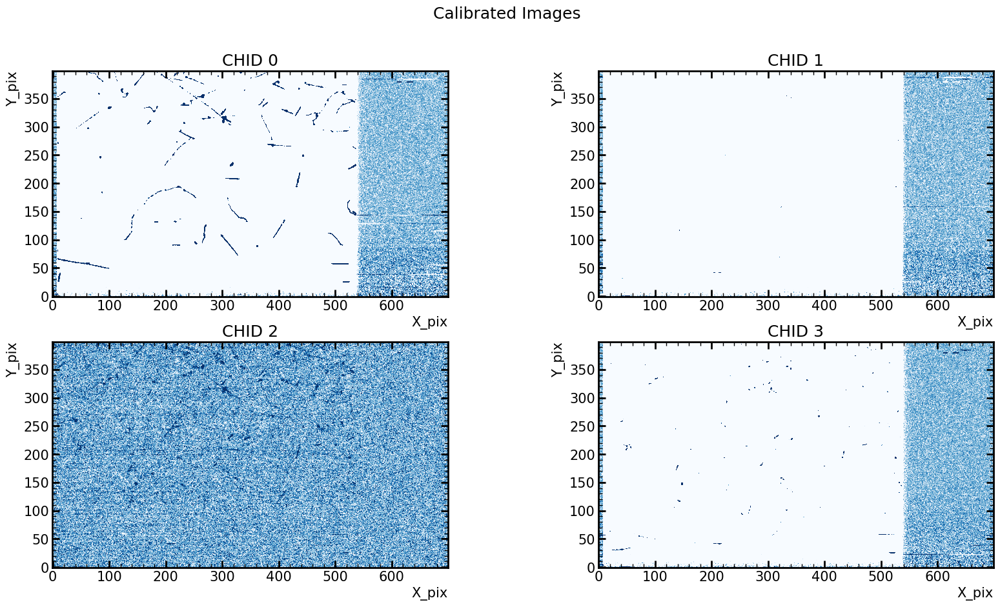

In [89]:
data_pre = precal(hdu_list,extensions=4)
gain, gain_err, data= LocalCalib(data_pre,extensions=4)
fig=plt.figure(figsize=(20,10))
cmap = mpl.cm.Blues_r
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.imshow(data[i],cmap=cmap,vmin=-1,vmax=1)
    plt.title('CHID '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
    print("CHID "+str(i)+' Gain:({:.2f} +- {:.2f})ADUs'.format(gain[i],gain_err[i]))
plt.suptitle('Calibrated Images')
#plt.savefig('IMAGES_POSCALIB.png', bbox_inches='tight', dpi=100)
    
plt.show()

    

11600.797102371307
11600.797102371307


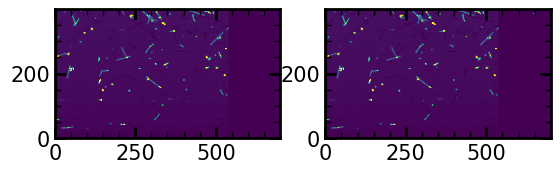

In [8]:
plt.subplot(121)
plt.imshow(data_pre[0],vmin=0,vmax=1000)
plt.subplot(122)
plt.imshow(data[0],vmin=0,vmax=1000)

print(str(data_pre[0].max()))
print(str(data.max()))

In [9]:
sigma, sigma_err = LocalSigma(data,extensions=4)
for i in range(4):
    print('CHID '+str(i),r' Noise: ({:.3f} +- {:.3f}) e-'.format(sigma[i],sigma_err[i]))

CHID 0  Noise: (0.223 +- 0.006) e-
CHID 1  Noise: (0.243 +- 0.008) e-
CHID 2  Noise: (0.698 +- 0.070) e-
CHID 3  Noise: (0.491 +- 0.037) e-


# Masking

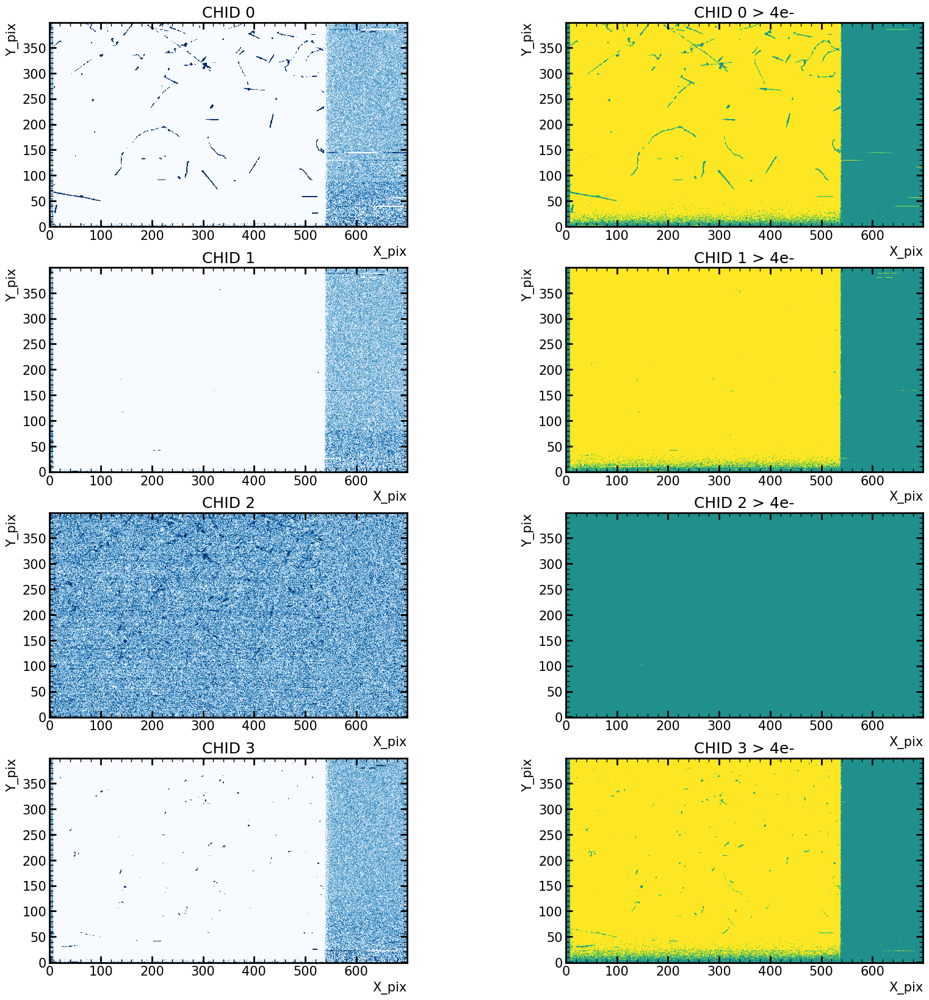

In [10]:
fig=plt.figure(figsize=(20,20))
for i in range(4):
    plt.subplot(4,2,2*(i+1)-1)
    plt.imshow(data[i],cmap=cmap, vmin=-1,vmax=1)
    plt.title('CHID '+str(i))
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
    plt.subplot(4,2,2*(i+1))
    plt.imshow(data[i]>4,vmin=-1,vmax=1)
    plt.title('CHID '+str(i)+' > 4e-')
    plt.ylabel('Y_pix')
    plt.xlabel('X_pix')
    # cax = plt.axes([0.85, 0.1, 0.075, 0.8])
    # plt.colorbar(cax=cax)
plt.show()

In [11]:
import skimage.measure as sk

### Etiqueta cada uno de los eventos
### y, utilizando __imshow__ podemos mostrar el numero del eventos dentro de la imagen

In [125]:
label,num_objects=ndimage.label(data[3]>180,structure=[[1,1,1],[1,1,1],[1,1,1]])

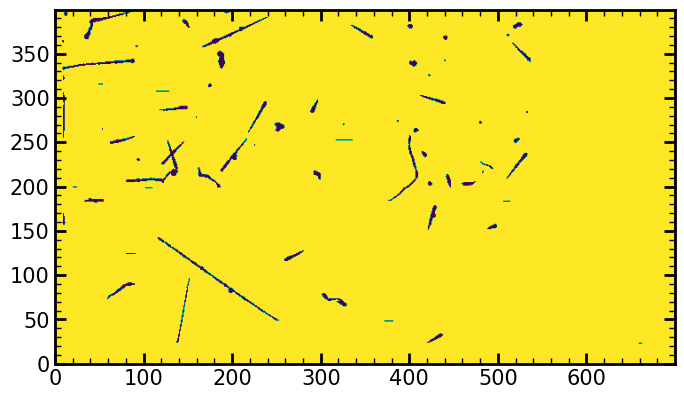

In [126]:
plt.figure(figsize=(8,7))
plt.imshow(label==0, cmap='viridis', vmax=1,vmin=0)
plt.show()

In [127]:
num_objects

71

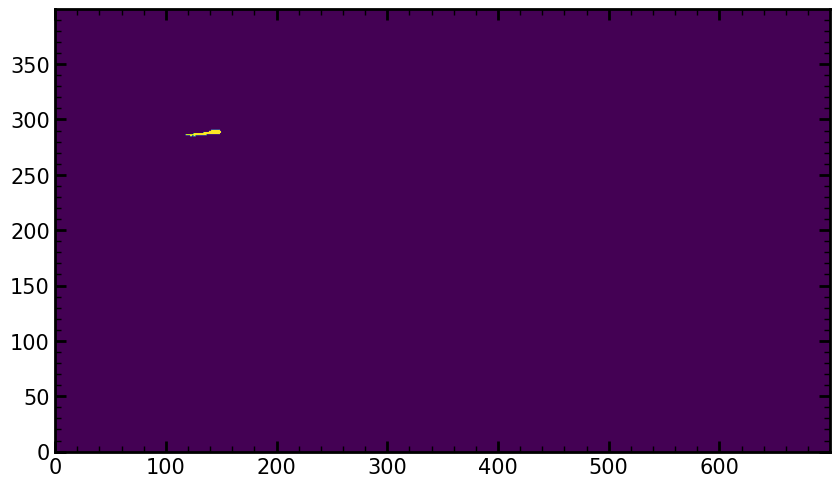

In [138]:
plt.figure(figsize=(10,10))
plt.imshow(label==45, cmap='viridis', vmax=1,vmin=0)
plt.show()

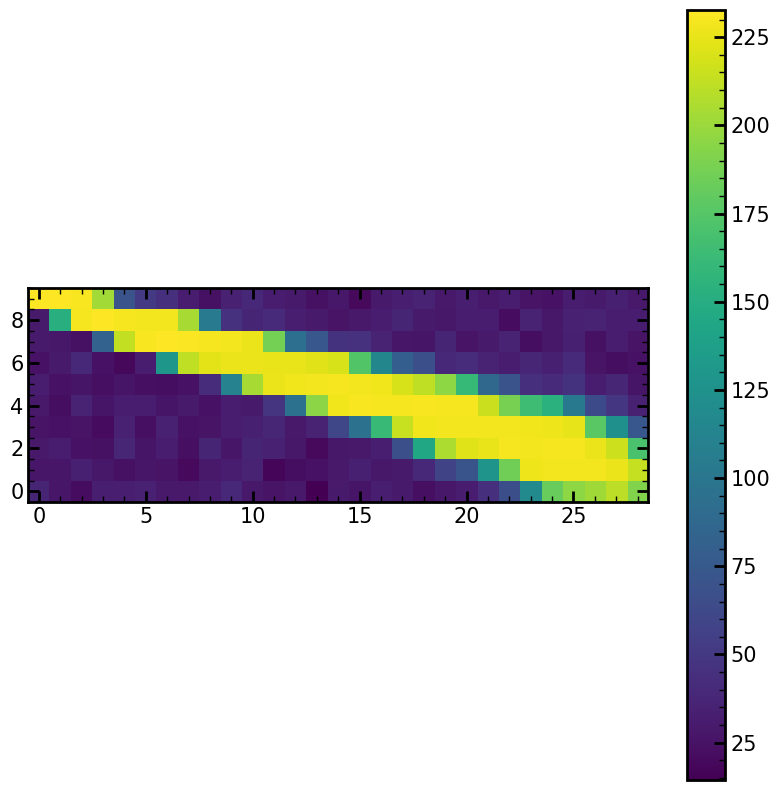

In [135]:

plt.figure(figsize=(10,10))
evento=data[3][ndimage.find_objects(label)[45]]
plt.imshow(evento, cmap='viridis')
plt.colorbar()
plt.show()

In [137]:
evento.sum()


26011.34702857488

Getting only the High Energy Events

In [18]:
def sum_intensity(region, intensities):
    return np.sum(intensities[region])

rps=sk.regionprops(label,intensity_image=data[0],cache=False, extra_properties=[sum_intensity])
areas=[r.area for r in rps]
energy=[r.sum_intensity for r in rps]
centr=[r.weighted_centroid for r in rps]
ecce=[r.eccentricity for r in rps]
dic_props={"areas":areas,"energias":energy,'centroid':centr, "excentricidade":ecce}

In [19]:
import skimage as ski
ski.__version__

'0.19.3'

In [20]:
df=pd.DataFrame.from_dict(dic_props)
df.index = np.arange(1, len(df)+1)
# df.head(35) #show dataframe

In [21]:
energias=dic_props["energias"]
exce=dic_props["excentricidade"]
hee_list=np.where((np.array(energias)>80) & (np.array(exce)!=1))[0].tolist() #index od the dictionary of events ---> TRESHOLD OF 80 ELECTRONS TO BE HE

In [22]:
areas=dic_props["areas"]
see_list=np.where((np.array(exce)==1) & (np.array(areas)>9))[0].tolist() 
see_list

[41]

In [23]:
label

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=int32)

Getting there positions

In [24]:
HE_events=np.zeros_like(label)
for event in hee_list:
    [x,y]=np.where(label==event+1)
    for i in range(len(x)):
        HE_events[x[i],y[i]]=1

In [25]:
SRE_events=np.zeros_like(label)
for event in see_list:
    [x,y]=np.where(label==event+1)
    for i in range(len(x)):
        SRE_events[x[i],y[i]]=1

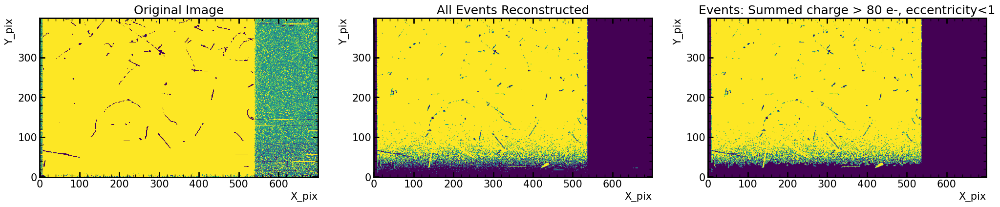

In [26]:
fig=plt.figure(figsize=(25,15))
plt.subplot(133)
plt.imshow(HE_events)
plt.title('Events: Summed charge > 80 e-, eccentricity<1')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
# plt.colorbar()
plt.subplot(132)
plt.title('All Events Reconstructed')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.imshow(label!= 0)
plt.subplot(131)
plt.imshow(data[0],vmin=-1,vmax=1)
plt.title('Original Image')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
# plt.savefig('IMAGES_RECOHE.png', bbox_inches='tight', dpi=100)

plt.show()

In [27]:
mask_bleeding=ndimage.binary_dilation(HE_events>0,structure=[[0,0,0],[0,1,1],[0,0,0]],
                                             iterations=40)*1.0#-(HE_events>0)*1.0

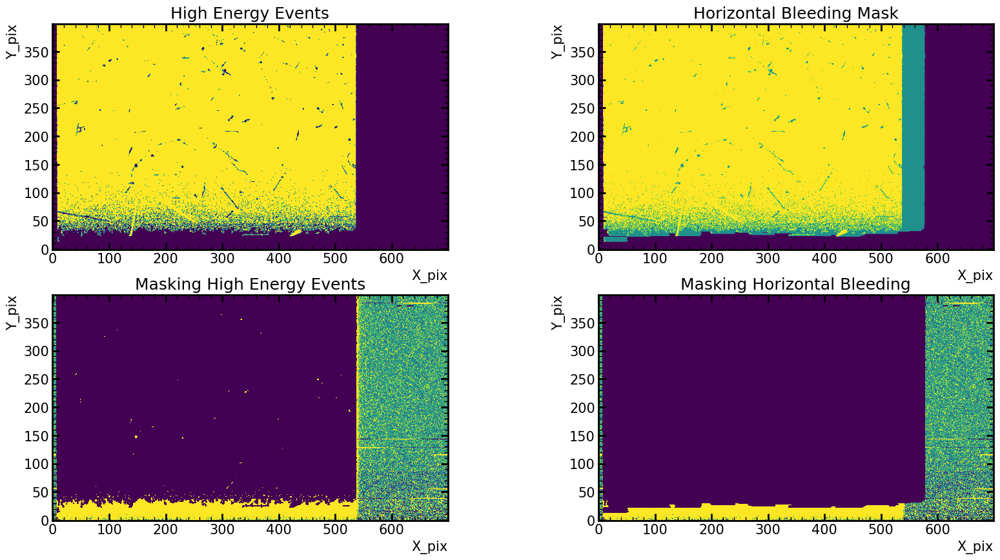

In [28]:
plt.figure(figsize=(20,10))
# plt.subplot(223)
# plt.imshow(data[0],vmin=-1,vmax=1)
# plt.title('Original Image')
plt.subplot(221)
plt.imshow(HE_events)
plt.title('High Energy Events')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.subplot(222)
plt.imshow(mask_bleeding+(HE_events>0)*1)
plt.title('Horizontal Bleeding Mask')

plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.subplot(223)
plt.imshow(data[0]+((HE_events>0))*-1e7,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')

# plt.colorbar()
plt.title('Masking High Energy Events')
plt.subplot(224)
plt.imshow(data[0]+((mask_bleeding+HE_events>0))*-1e7,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')

plt.title('Masking Horizontal Bleeding')
#plt.savefig('IMAGES_HBLEED.png', bbox_inches='tight', dpi=100)

plt.show()

In [29]:
maskV_bleeding=ndimage.morphology.binary_dilation(HE_events>0,structure=[[0,0,0],[0,1,0],[0,1,0]],
                                             iterations=20)*1.0#-(HE_events>0)*1.0

/tmp/ipykernel_45446/684858339.py:1: DeprecationWarning: Please use `binary_dilation` from the `scipy.ndimage` namespace, the `scipy.ndimage.morphology` namespace is deprecated.
  maskV_bleeding=ndimage.morphology.binary_dilation(HE_events>0,structure=[[0,0,0],[0,1,0],[0,1,0]],


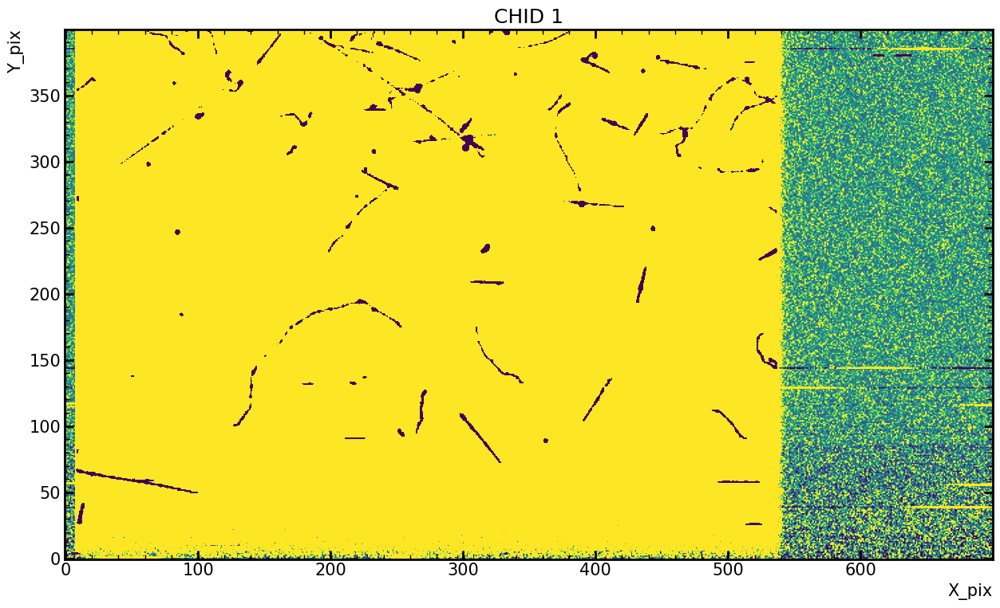

In [30]:
fig=plt.figure(figsize=(15,10))
plt.imshow(data[0],vmin=-1,vmax=1)
plt.title('CHID 1')
# plt.savefig('IMAGES_chid1.png', bbox_inches='tight', dpi=100)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.show()

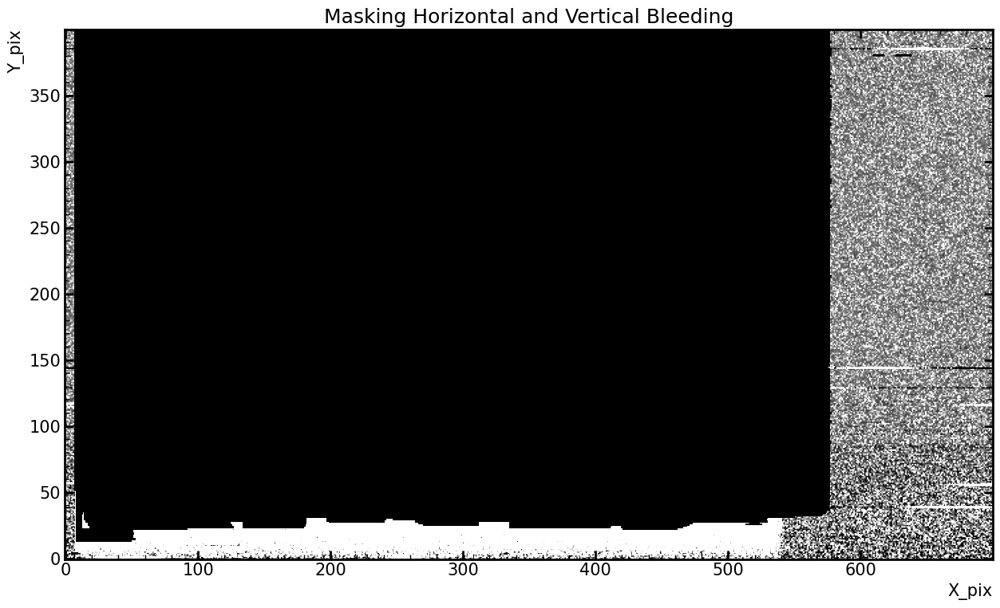

In [31]:
fig=plt.figure(figsize=(15,10))
# plt.imshow(data[0]+((maskV_bleeding+mask_bleeding+HE_events>0))*-1e7,vmin=-1,vmax=1, cmap='gray')
plt.imshow(data[0]+((maskV_bleeding+mask_bleeding+HE_events>0))*-1e7,vmin=-1,vmax=1, cmap='gray')
plt.title('Masking Horizontal and Vertical Bleeding')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')

#plt.savefig('IMAGES_BLEED.png', bbox_inches='tight', dpi=100)

plt.show()

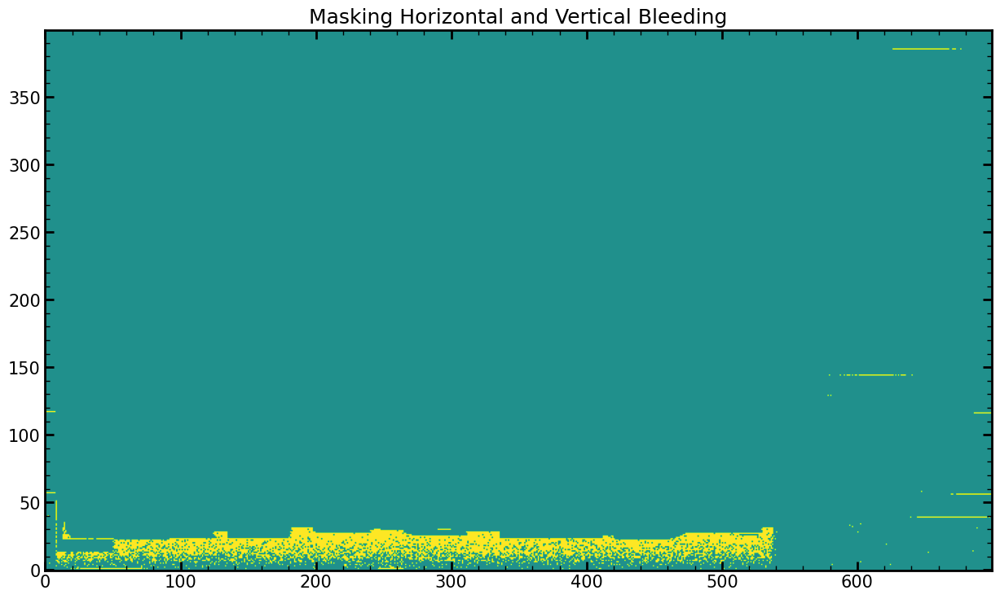

In [32]:
plt.figure(figsize=(15,10))
plt.imshow((data[0]+((maskV_bleeding+mask_bleeding+HE_events>0))*-1e7)>4,vmin=-1,vmax=1)
plt.title('Masking Horizontal and Vertical Bleeding')
plt.show()

In [33]:
matriz2, dmask=no_sr(data[0]+((maskV_bleeding+mask_bleeding+HE_events))*-1e7,threshold=3,trem=20)

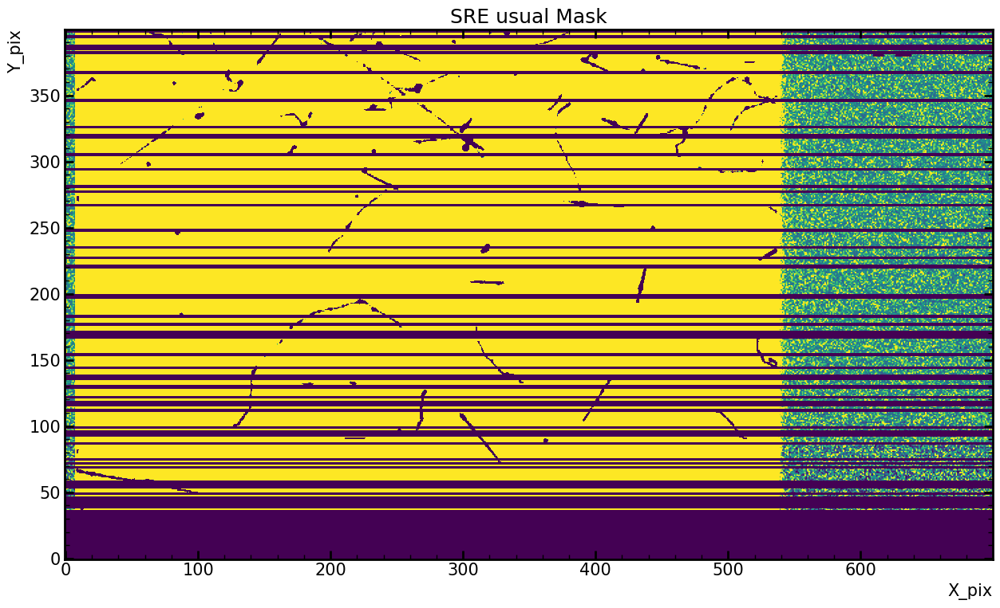

In [34]:
fig=plt.figure(figsize=(15,10))
plt.imshow(data[0]-dmask*1e7,vmin=-1,vmax=1)
plt.title('SRE usual Mask')
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
#plt.savefig('IMAGES_SRE_std.png', bbox_inches='tight', dpi=100)
plt.show()

In [35]:
pre_sre=ndimage.label((data[0]+((maskV_bleeding+mask_bleeding+HE_events))*-1e7)>1.5,structure=[[0,0,0],[1,1,1],[0,0,0]])[0]

In [36]:
rps=sk.regionprops(pre_sre,cache=False)
areas=[r.area for r in rps]

SRE_events=np.zeros_like(pre_sre)
for event in np.where(np.array(areas)>1)[0].tolist():
    [x,y]=np.where(pre_sre==event+1)
    for i in range(len(x)):
        SRE_events[x[i],y[i]]=1

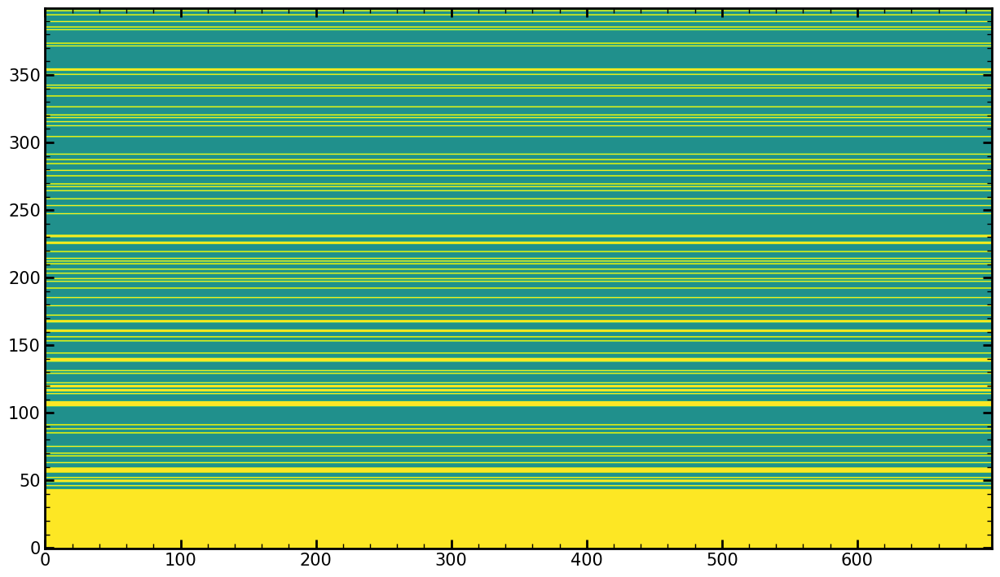

In [37]:
SRE_mask=np.zeros_like(SRE_events)
for y in np.unique(np.where(SRE_events==1)[0]).tolist(): SRE_mask[y,:]=1
plt.figure(figsize=(15,10))
plt.imshow(SRE_mask,vmin=-1,vmax=1)
plt.show()

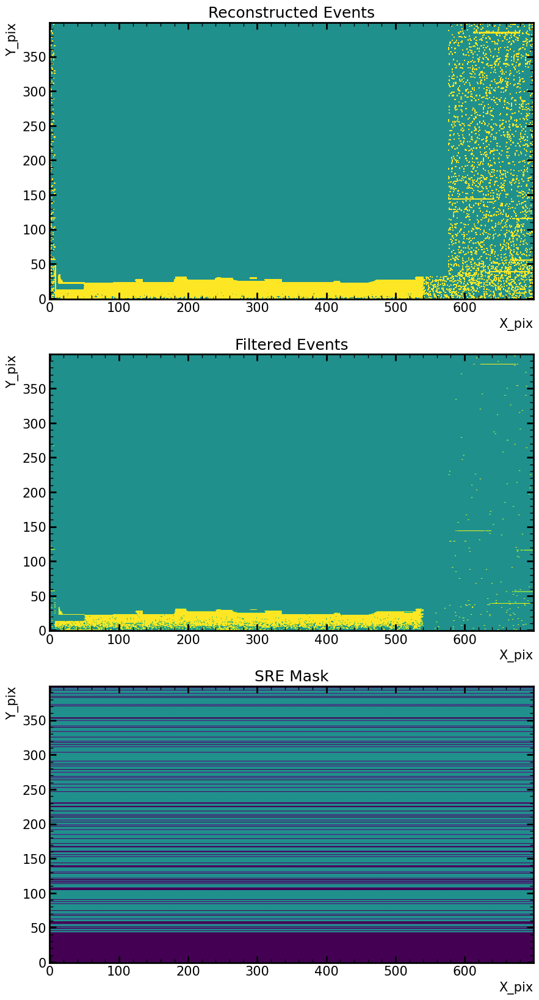

In [38]:
plt.figure(figsize=(25,20))
plt.subplot(311)
plt.imshow(pre_sre,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('Reconstructed Events')
plt.subplot(312)
plt.imshow(SRE_events,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('Filtered Events')
plt.subplot(313)
plt.imshow(-SRE_mask,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('SRE Mask')
# plt.savefig('IMAGES_SRE_pre.png', bbox_inches='tight', dpi=100)

plt.show()

In [39]:
np.unique(np.where(SRE_events==1)[0])

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  46,  49,  50,  52,  56,  57,  58,  59,
        63,  68,  70,  75,  85,  88,  91, 105, 106, 107, 108, 114, 116,
       117, 119, 120, 122, 129, 131, 138, 139, 140, 144, 153, 156, 160,
       161, 167, 168, 172, 179, 185, 192, 197, 199, 203, 206, 210, 212,
       214, 219, 225, 226, 230, 231, 247, 253, 258, 264, 267, 269, 275,
       279, 284, 287, 291, 304, 312, 315, 318, 320, 326, 334, 340, 342,
       350, 353, 354, 371, 373, 383, 385, 389, 394, 397])

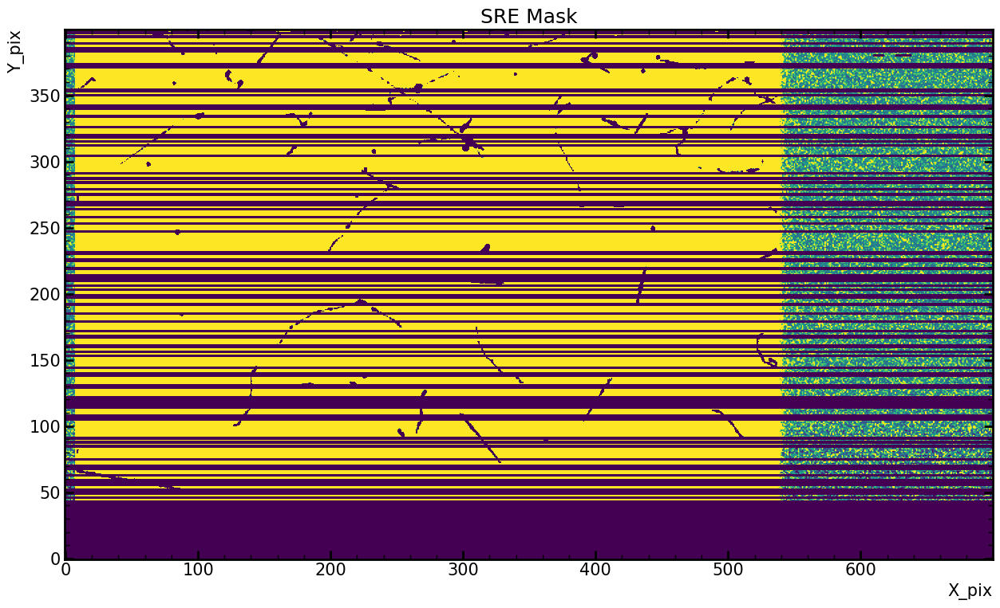

In [40]:
fig=plt.figure(figsize=(15,10))
plt.imshow(data[0]-1e7*SRE_mask,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('SRE Mask')
#plt.savefig('IMAGES_SRE_MASK.png', bbox_inches='tight', dpi=100)
plt.show()

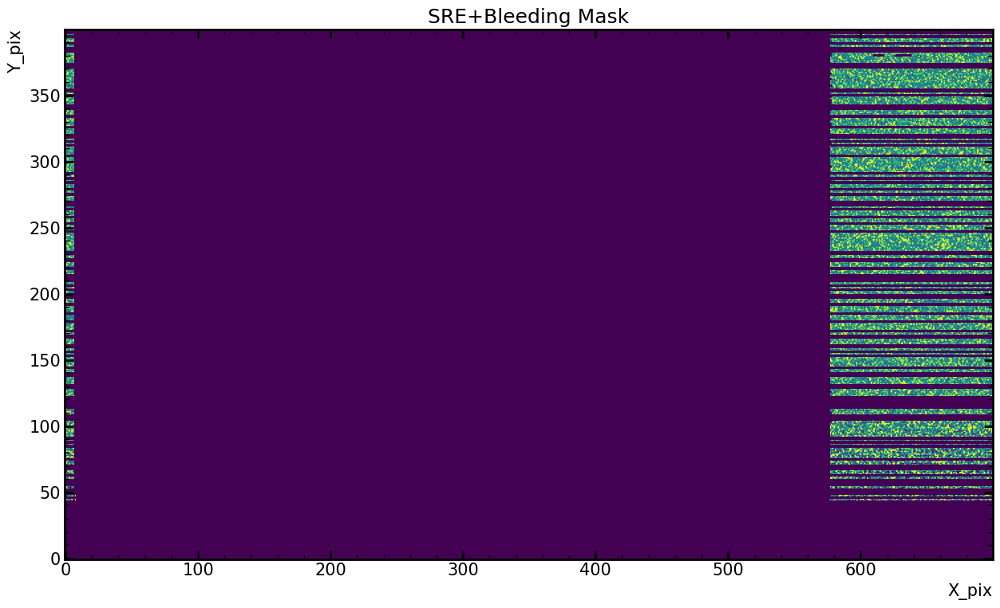

In [41]:
fig=plt.figure(figsize=(15,10))
plt.imshow(data[0]-1e7*(maskV_bleeding+mask_bleeding+SRE_mask),vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('SRE+Bleeding Mask')

#plt.savefig('IMAGES_TOTALMASK.png', bbox_inches='tight', dpi=100)
plt.show()

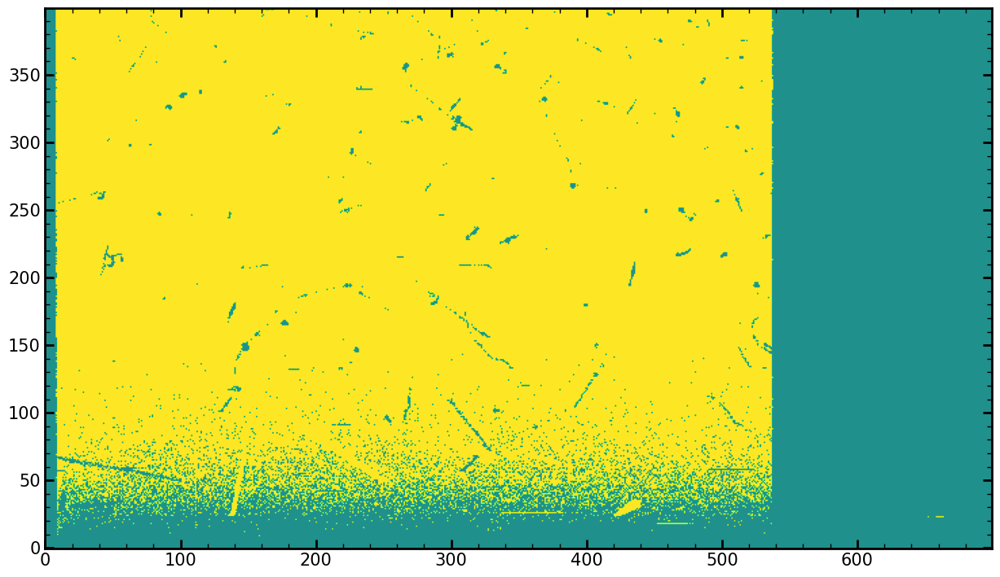

In [42]:
plt.figure(figsize=(15,10))
plt.imshow(label!=0,vmin=-1,vmax=1)
plt.show()

In [43]:
def sum_intensity(region, intensities):
    return np.sum(intensities[region])

rps=sk.regionprops(label,intensity_image=data[1],cache=False, extra_properties=[sum_intensity])
areas=[r.area for r in rps]
energy=[r.sum_intensity for r in rps]
centr=[r.weighted_centroid for r in rps]
ecce=[r.eccentricity for r in rps]
dic_props={"areas":areas,"energias":energy,'centroid':centr, "excentricidade":ecce}

In [44]:
flag0=[]
for i in range(len(centr)):
    if int(centr[i][0]) not in np.unique(np.where(SRE_events==1)[0]).tolist():
        
        flag0.append(i)

In [45]:
flag0_events=np.zeros_like(label)
for event in flag0:
    [x,y]=np.where(label==event+1)
    for i in range(len(x)):
        flag0_events[x[i],y[i]]=1

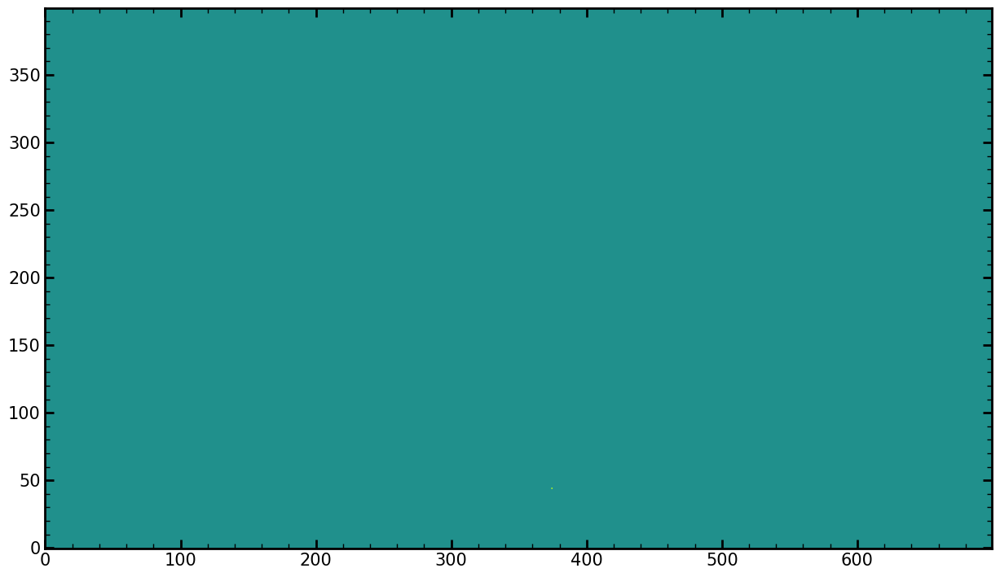

In [46]:
plt.figure(figsize=(15,10))
plt.imshow(flag0_events,vmin=-1,vmax=1)
plt.show()

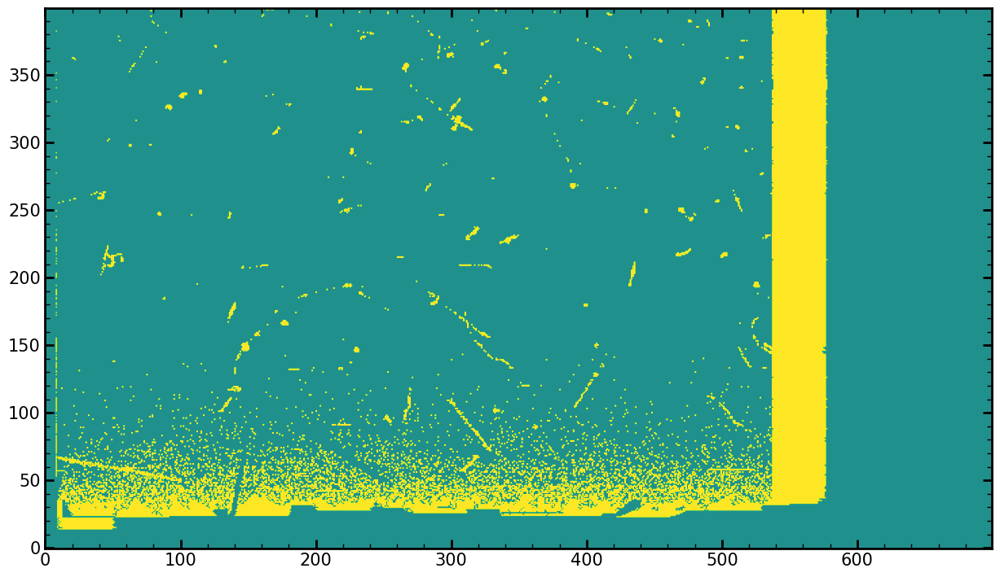

In [47]:
plt.figure(figsize=(15,10))
plt.imshow(maskV_bleeding+mask_bleeding-2*HE_events,vmin=-1,vmax=1)
plt.show()

In [48]:
type(centr[0] )

tuple

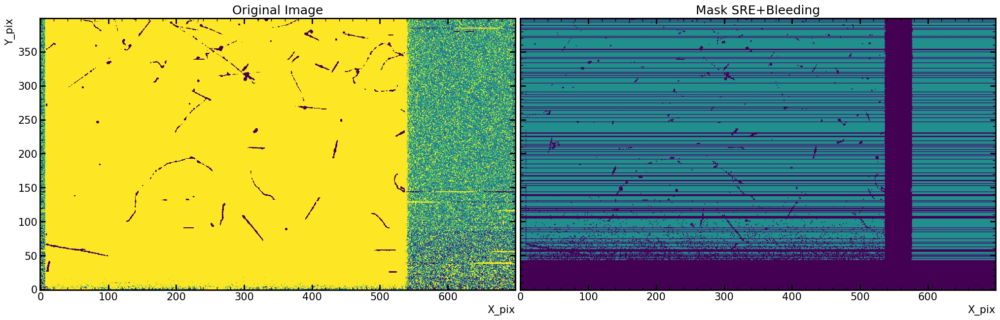

In [49]:
fig=plt.figure(figsize=(25,15))
plt.subplot(121)
plt.title('Original Image')
plt.imshow(data[0],vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.subplot(122)
plt.imshow(-(maskV_bleeding+mask_bleeding-2*HE_events+SRE_mask),vmin=-1,vmax=1)
plt.title('Mask SRE+Bleeding')
plt.tick_params('y', labelleft=False)
plt.subplots_adjust(wspace=0.01)
plt.xlabel('X_pix')
#plt.savefig('Imageandmask.png', bbox_inches='tight', dpi=100)
plt.show()

In [50]:
# fig=plt.figure(figsize=(10,5))
# plt.imshow(data[0]-event_halo_SR_mask,vmin=-1,vmax=1)
# plt.ylabel('Y_pix')
# plt.xlabel('X_pix')
# plt.title('SRE+Bleeding Mask+ Bleeding Halo')
# #plt.savefig('SER.png', bbox_inches='tight', dpi=100)
# plt.colorbar()
# plt.show()

# SINGLE ELECTRON RATE

In [51]:
event_mask=maskV_bleeding+mask_bleeding
event_halo_mask = ndimage.binary_dilation(
        event_mask>0,
        iterations = 10,
        structure = ndimage.generate_binary_structure(rank=2, connectivity=2) # == [[1,1,1],[1,1,1],[1,1,1]]
    )
event_halo_SR_mask = np.array(SRE_mask,dtype=bool)|event_halo_mask

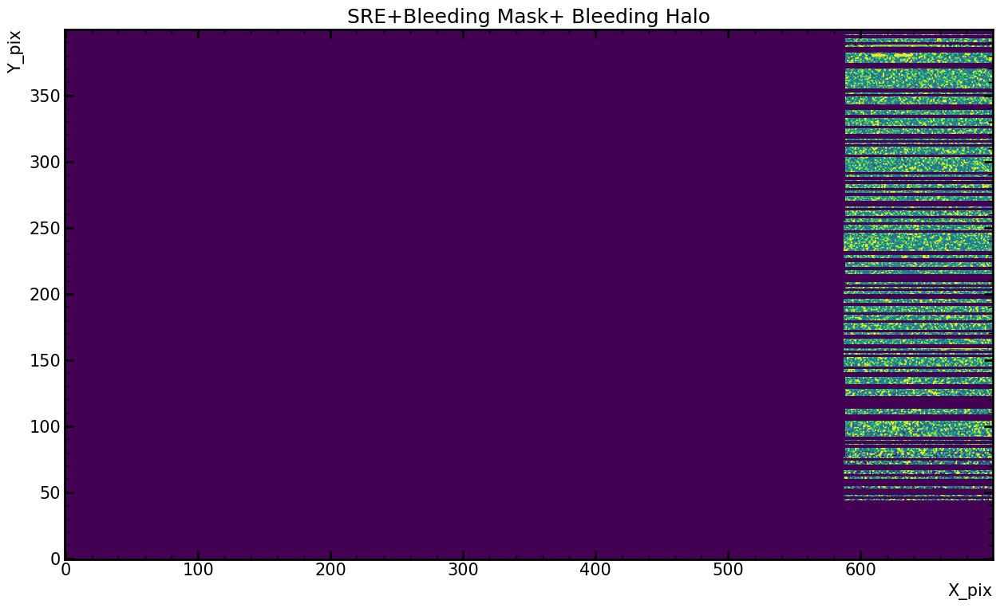

In [52]:
fig=plt.figure(figsize=(15,10))
plt.imshow(data[1]-1e7*event_halo_SR_mask,vmin=-1,vmax=1)
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.title('SRE+Bleeding Mask+ Bleeding Halo')
plt.savefig('SER.png', bbox_inches='tight', dpi=100)
plt.show()

#### Convolution Mask is a slice of the size of the entire CCD. subtract the first and last 5 rows on vertical; and subtract the first 5 and last 5 plus overscan region
#### Masking process is using np.where, replacing the masked pixels by np.nan value
#### Making histogram

In [53]:
convolution_mask = np.s_[5:int(hdu_list[1].header["CCDNROW"])-5, 15:-(osc+5)] #Means active area of entire CCD (slice(5, 1273, None), slice(15, -168, None)); if the slice is bigger it ok, there is no prob
masked_data = np.where(event_halo_SR_mask , np.nan, data[1] ) #aplying the mask to the data
masked_hist, bins = np.histogram( masked_data[convolution_mask], np.arange(-0.5, 2.5, .01) )
x = (bins[1:]+bins[:-1])/2 #get a mean value of the data and reshape, to adjust the size of the bins in histogram

In [54]:
sigma_list, sigma_errLlist=LocalSigma(data,extensions=4)
global sigma
sigmaN=sigma_list[1]
def poisson_normN(x, mu, A, lamb, Nmax=5): #sigma parameter global 
    y = 0.
    for i in range(0, Nmax+1):
        y += (lamb**i)/float(math.factorial(i)) *np.exp(-0.5*((x-i-mu-lamb)/float(sigmaN))**2)
    return A*np.exp(-lamb)*y/(np.sqrt(2*np.pi*sigmaN**2))

In [55]:

try:
    popt, pcov = curve_fit( 
        poisson_normN, 
        x, 
        masked_hist, 
        p0=[-0.4, 1000, 0.05],
    )
except (RuntimeError,OptimizeWarning,RuntimeWarning):
    print( f"Error - dc fit failed at" )

In [56]:
print(popt)
chid=1
start=parse(hdu_list[chid].header["DATESTART"]+"Z").timestamp()
end=parse(hdu_list[chid].header["DATEEND"]+"Z").timestamp()
time=datetime.timedelta(seconds=end-start)
readout_time=time.total_seconds()/86400 #readout time in days

exposure_time=readout_time*int(hdu_list[chid].header["CCDNROW"])/(2*int(hdu_list[chid].header["NROW"]))
print(exposure_time)
perr = np.sqrt(np.diag(pcov))
dc = popt[2]/exposure_time # electron/pix/day
dc_err = perr[2]/exposure_time # electron/pix/day
print(dc,dc_err)

[-4.00000000e-01 -8.84391653e-16  5.00000000e-02]
0.08327708333333333
0.6004052730121078 9.465436001959142e-10


/tmp/ipykernel_45446/1312486600.py:4: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  plt.yscale('log')


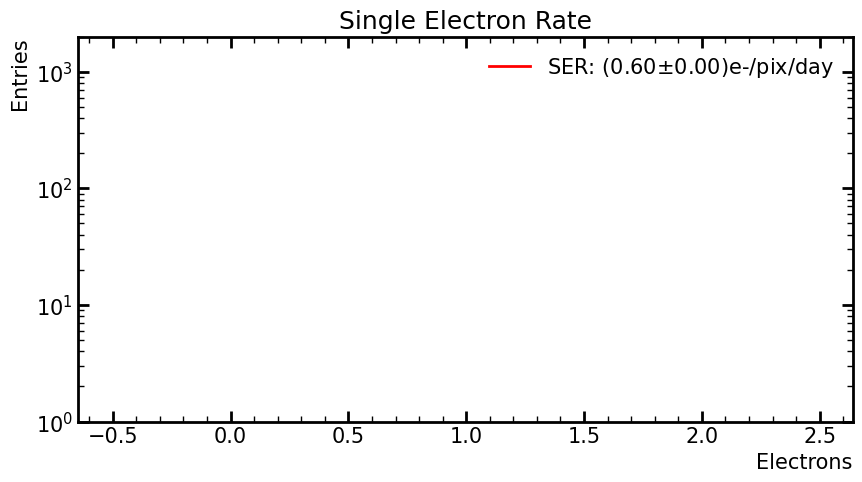

In [57]:
fig=plt.figure(figsize=(10,5))
plt.bar(x,masked_hist,width=0.01)
plt.plot(x,poisson_normN(x,*popt),linewidth=2,c='r',label=r'SER: ({:.2f}$\pm${:.2f})e-/pix/day'.format(dc,dc_err))
plt.yscale('log')
plt.ylim(1,2e3)
plt.ylabel('Entries')
plt.xlabel('Electrons')
plt.title('Single Electron Rate')
plt.legend()
#plt.savefig('SER_HISTO.png', bbox_inches='tight', dpi=100)

plt.show()

## Spurious Charge

1.251111111111111
4504
2578.523914285714


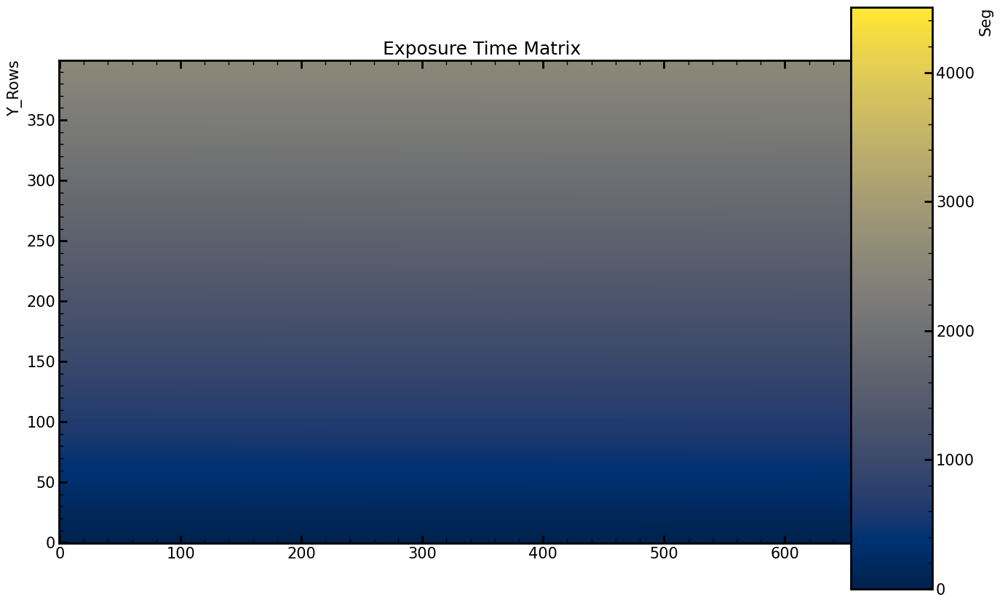

In [58]:
ExpoMatrix, Ttot, NRow, NCol, NSamp= totTime(path)
fig=plt.figure(figsize=(15,10))
plt.subplot(1,1,1)

cmap = mpl.cm.cividis

#plt.imshow(ExpoMatrix,cmap=cmap,vmin=0,vmax=Ttot/3600) #Horas
plt.imshow(ExpoMatrix,cmap=cmap, vmin=0,vmax=Ttot) #Segundos

plt.title('Exposure Time Matrix')
plt.ylabel('Y_Rows')
plt.xlabel('X_Cols')

cax = plt.axes([0.85, 0.1, 0.075, 0.8])
plt.colorbar(cax=cax)
plt.ylabel('Seg')


# ExpoMatrix
print(Ttot/60/60)
print(Ttot)

print(ExpoMatrix.max())

HEF=0.0160857142857195 VEF=6.434285714285723


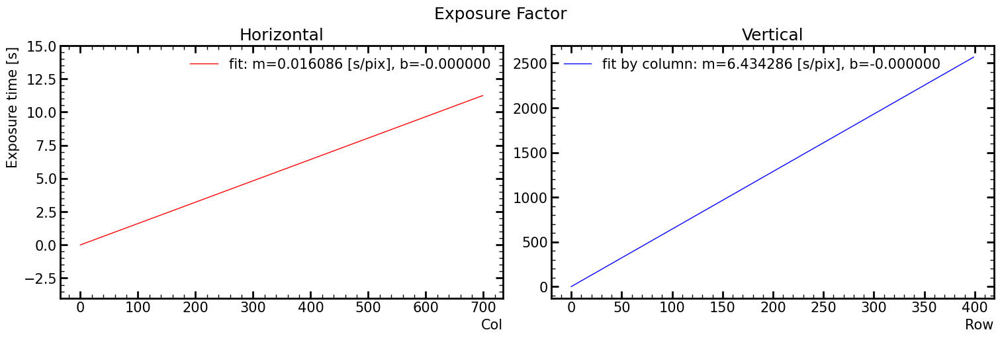

In [59]:
HEF, VEF = exposureFactor(path) #Exposure Factor in [s/pix]

fig_all, axs_all = plt.subplots(nrows=1, ncols=2, figsize=(15, 5),constrained_layout=True)		# Create figures
fig_all.suptitle('Exposure Factor', fontsize='large')
axs_all[0].set_title('Horizontal')
axs_all[0].set_ylim([-4, 15])
axs_all[0].set_ylabel('Exposure time [s]')
axs_all[0].set_xlabel('Col')
axs_all[1].set_xlabel('Row')
axs_all[0].plot(range(0,len(ExpoMatrix[0])), line(range(0,len(ExpoMatrix[0])), HEF[0], HEF[1]),'r-', label='fit: m=%f [s/pix], b=%f' % tuple(HEF))


axs_all[0].legend()

axs_all[1].set_title('Vertical')
axs_all[1].plot(range(0,len(ExpoMatrix[:,0])), line(range(0,len(ExpoMatrix[:,0])), VEF[0], VEF[1]),'b-', label='fit by column: m=%f [s/pix], b=%f' % tuple(VEF))
axs_all[1].legend()
plt.show()

media on Row=23.37465827189772, stdDev on y=8.919129227645513
Check
media on Col=19.679937590978415, stdDev on y=11.254181675187578


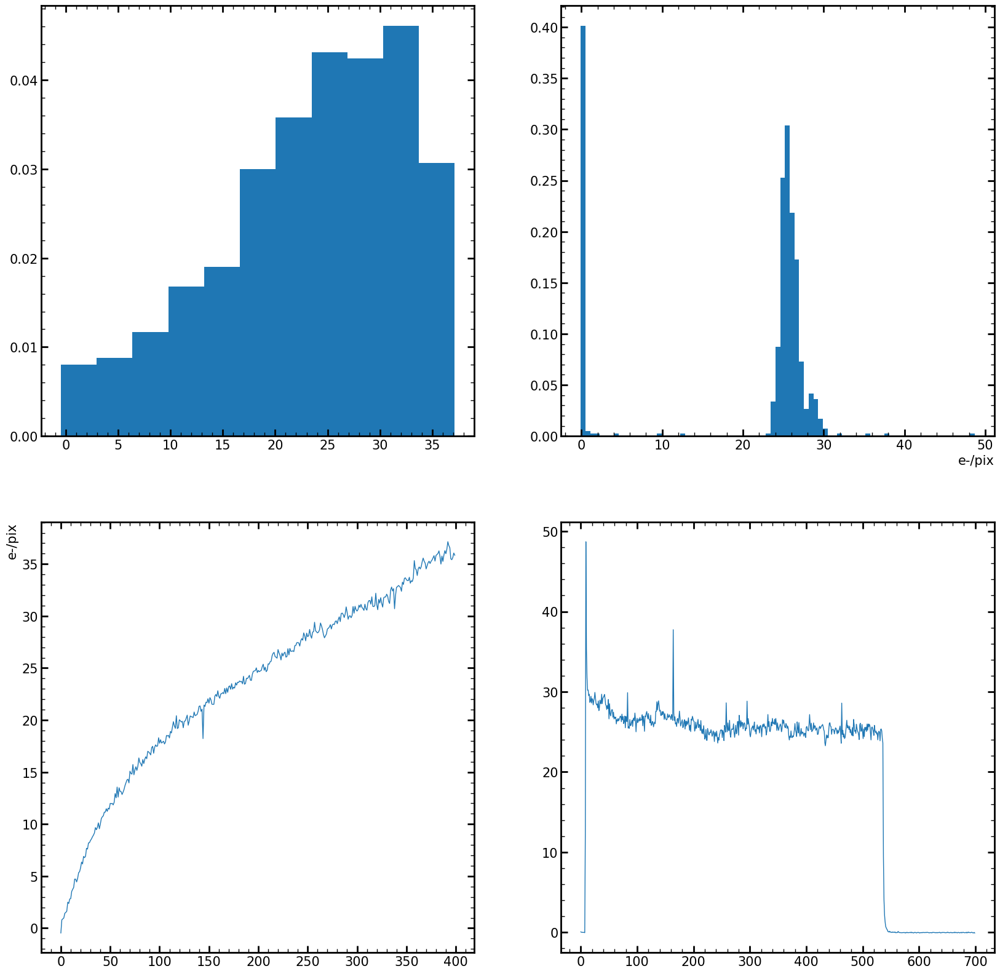

In [60]:

data_masked=data[0]#-1e7*(maskV_bleeding+mask_bleeding+SRE_mask)
data_Row, data_Col, Row_bins, Col_bins, Row_hist, Col_hist = hist_RowColumn(data_masked)

fig_all, axs_all = plt.subplots(2, 2, figsize=(20, 20))		# Create figures


axs_all[0][0].hist(data_Row, Row_bins, density=True)

axs_all[0][1].hist(data_Col, Col_bins, density=True)

axs_all[1][0].plot(data_Row)

axs_all[1][1].plot(data_Col)

axs_all[1][0].set_ylabel('e-/pix')
axs_all[0][1].set_xlabel('e-/pix')

plt.show()


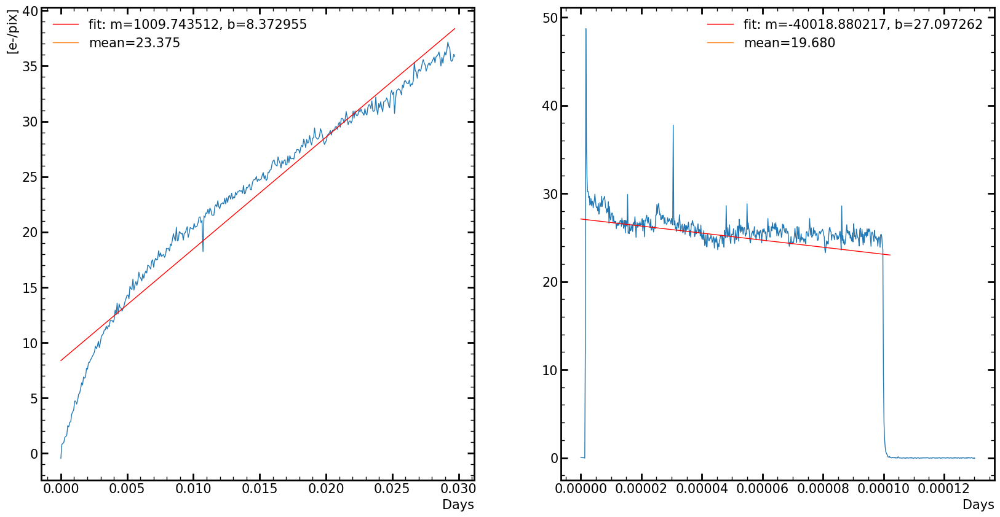

In [61]:
#NROW650_NCOL700
fig_all, axs_all = plt.subplots(1, 2, figsize=(20, 10))		# Create figures
x_data=[]
i=0

for value in data_Row:  
            x_data.append(i)
            i+=1
Xdata=np.array(x_data)*VEF[0]/86400

axs_all[0].plot(Xdata, data_Row) #Xdata[Pix]*VEF[S/Pix], data_Row[e-]*86400[s/day]/VEF[s/pix]
popt, pcov = curve_fit(line, Xdata, data_Row)
axs_all[0].plot(Xdata, line(Xdata, popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
rowValues=popt
axs_all[0].plot(np.mean(data_Row), label="mean=%5.3f" % np.mean(data_Row) )
axs_all[0].set_ylabel('[e-/pix]')
axs_all[0].set_xlabel('Days')
axs_all[0].legend()

x_data=[]
i=0

for value in data_Col:  
            x_data.append(i)
            i+=1
Xdata=np.array(x_data)*HEF[0]/86400

axs_all[1].plot(Xdata, data_Col)
popt, pcov = curve_fit(line, Xdata[:550], data_Col[:550])
axs_all[1].plot(Xdata[:550], line(Xdata[:550], popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
colValues=popt
axs_all[1].plot(np.mean(data_Col[:550]), label="mean=%5.3f" % np.mean(data_Col) )
axs_all[1].set_xlabel('Days')
axs_all[1].legend()

## TO DO: Enmascarar los datos


In [62]:
ma.masked_array(data[0], mask=event_halo_mask)

masked_array(
  data=[[-24.19376663793019, -4.921158856009378, -1.0634611965167997,
         ..., 1.6929188052361113, 0.9004583781908572,
         0.12013904758975386],
        [1.867773596923814, 2.4124871858172297, 0.5299233607178602, ...,
         0.31722305099278714, 0.38205004175931595, -0.896978762417617],
        [-1.4377635400456814, -0.3788391185790658, -0.9542318898958164,
         ..., -1.3445656894821405, 1.5469409524131368,
         0.5785827853679932],
        ...,
        [--, --, --, ..., 0.19833480852360916, 1.5646432740886842,
         -0.12169023021775575],
        [--, --, --, ..., -0.09724059707746346, -0.3358069231145576,
         -0.07399620457964311],
        [--, --, --, ..., -0.35930804196965604, -0.01796120714418968,
         -0.21883903651012443]],
  mask=[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [ True,  True,  True,

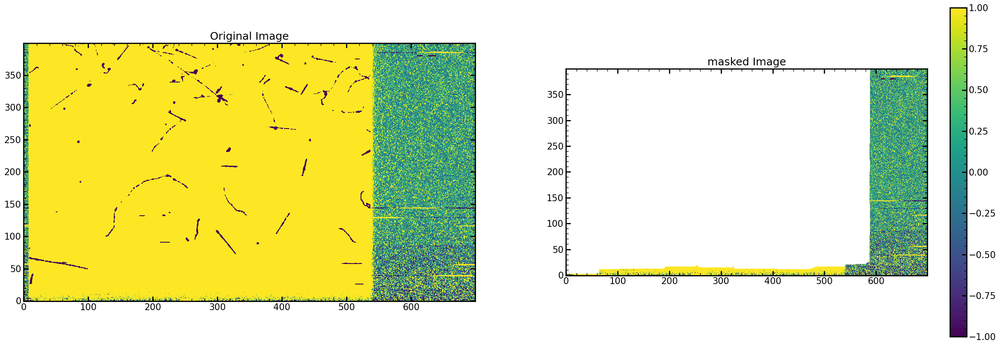

In [63]:
fig_all, axs_all = plt.subplots(1, 2, figsize=(30, 10))		# Create figures
plt.subplot(121)
plt.title('Original Image')
plt.imshow(data[0],vmin=-1,vmax=1)

plt.subplot(122)
plt.title('masked Image')
plt.imshow(ma.masked_array(data[0], mask=event_halo_mask),vmin=-1,vmax=1)


#cax = plt.axes([0.85, 0.1, 0.075, 0.8])
plt.colorbar()#cax=cax)



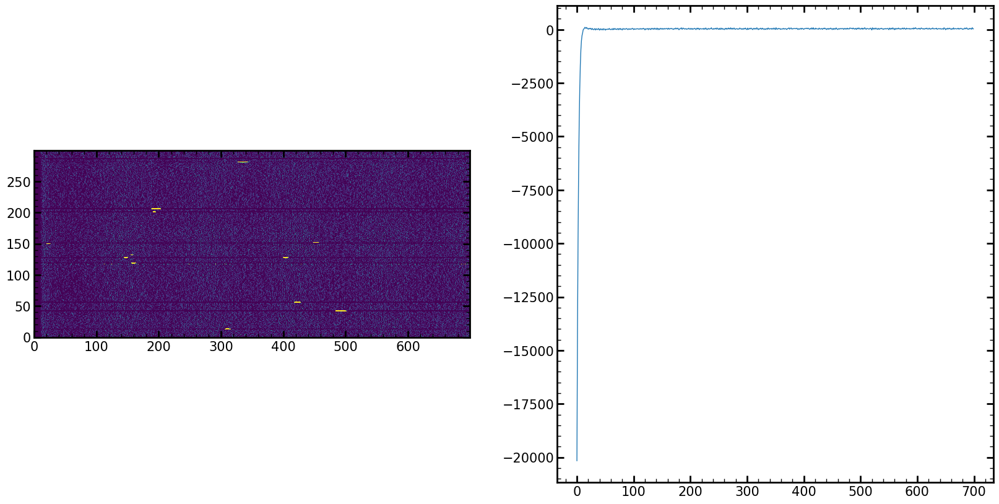

In [64]:
with open('/home/oem/Software/cursoInstrumentacion_2022/ClasesPy/70 - ICN_LabDet/rows_81_0.npy', 'rb') as f: #Este archivo ya no esta
     rowMatrix = np.load(f)

median=np.median(rowMatrix, axis=0)
mean=np.mean(rowMatrix,axis=0)

fig, axs_all = plt.subplots(1,2, figsize=(20,10))
axs_all[0].imshow(rowMatrix, vmax=1000, vmin=0)
axs_all[1].plot(median)




plt.show()

In [65]:
x_data=[]
i=0
for value in median:  
            x_data.append(i)
            i+=1
Xdata=np.array(x_data)*.02/86400

In [66]:
median=median/200

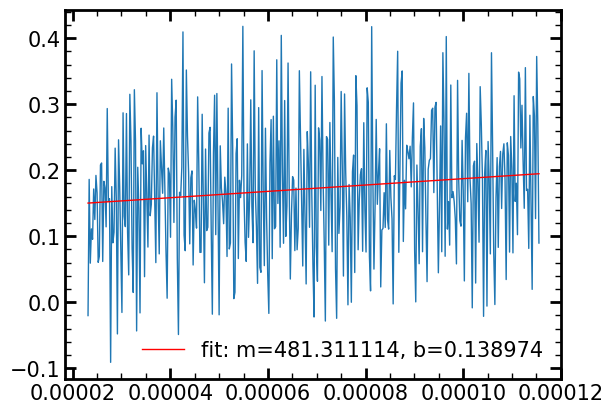

In [67]:

plt.plot(Xdata[100:500], median[100:500])
popt, pcov = curve_fit(line, Xdata[100:500], median[100:500])
plt.plot(Xdata[100:500], line(Xdata[100:500], popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
plt.legend()

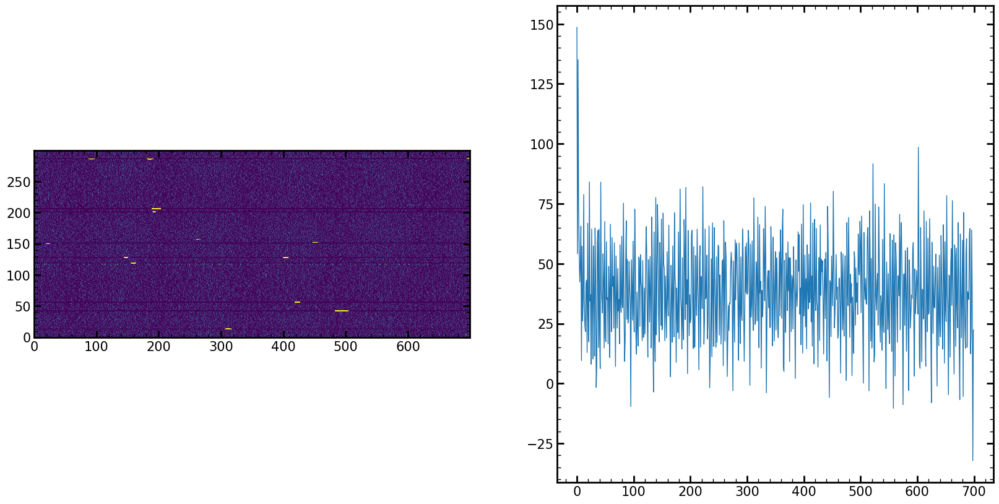

In [68]:
with open('/home/oem/Software/cursoInstrumentacion_2022/ClasesPy/70 - ICN_LabDet/rows_81_1.npy', 'rb') as f:
     rowMatrix = np.load(f)

median=np.median(rowMatrix, axis=0)
mean=np.mean(rowMatrix,axis=0)

fig, axs_all = plt.subplots(1,2, figsize=(20,10))
axs_all[0].imshow(rowMatrix, vmax=1000, vmin=0)
axs_all[1].plot(median)

median=median/200
plt.show()

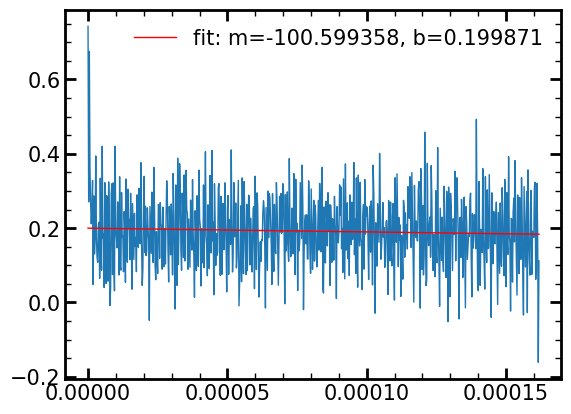

In [69]:
plt.plot(Xdata, median)
popt, pcov = curve_fit(line, Xdata, median)
plt.plot(Xdata, line(Xdata, popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
plt.legend()

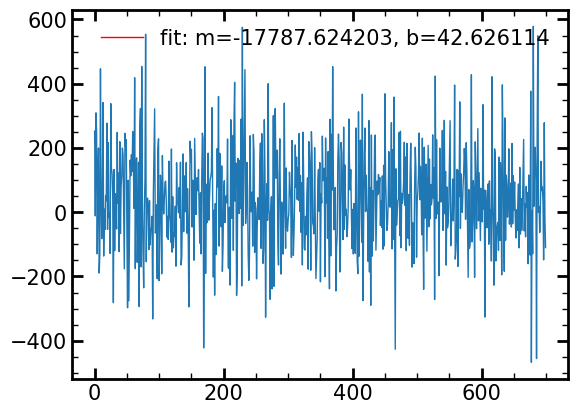

In [70]:
plt.plot(rowMatrix[10])
popt, pcov = curve_fit(line, Xdata, rowMatrix[10])
plt.plot(Xdata, line(Xdata, popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
plt.legend()

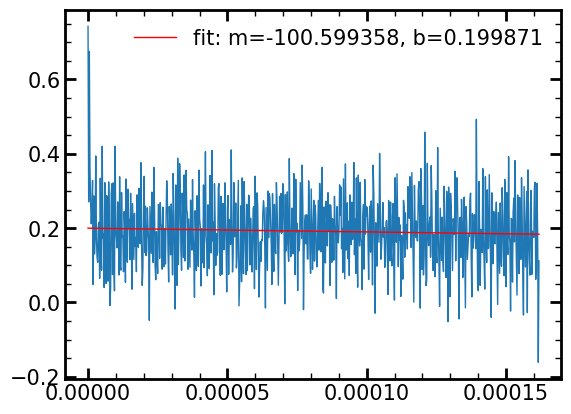

In [71]:

#plt.plot(Xdata[100:500], median[100:500])
plt.plot(Xdata, median)
popt, pcov = curve_fit(line, Xdata, median)
plt.plot(Xdata, line(Xdata, popt[0], popt[1]), 'r-', label='fit: m=%f, b=%f' % tuple(popt)) #plot de xdata vs f(xdata)
plt.legend()

# Notas para el seminario de Alexis Feb/marzo 23

In [72]:
path='/home/oem/datosFits/07SEP2022/proc_skp_mod9_wfr13_Vvtest_vthswings2.5_sh2.5_oh-2.5_EXPOSURE7200_NSAMP4_NROW1300_NCOL1200_img_10.fits'
hdu_list = fits.open(path)
print(hdu_list.info())
print('----------------')
# hdu_list[0].header
cmap = mpl.cm.cividis

fig=plt.figure(figsize=(15,10))
plt.subplot(1,1,1)

plt.imshow(hdu_list[0].data-np.median(hdu_list[0].data),cmap=cmap,vmin=0,vmax=210500)
plt.title('CHID '+str(0))
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
plt.suptitle('No Calibrated Image: 2hrs Exposure Time')
cax = plt.axes([0.85, 0.1, 0.075, 0.8])
plt.colorbar(cax=cax)
plt.ylabel('ADU')

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/home/oem/datosFits/07SEP2022/proc_skp_mod9_wfr13_Vvtest_vthswings2.5_sh2.5_oh-2.5_EXPOSURE7200_NSAMP4_NROW1300_NCOL1200_img_10.fits'

[4.43833019]
[1042.5462597]
[820.97765119]
[1204.26447435]
CHID 0 Gain:(2105.78 +- 173.35)ADUs


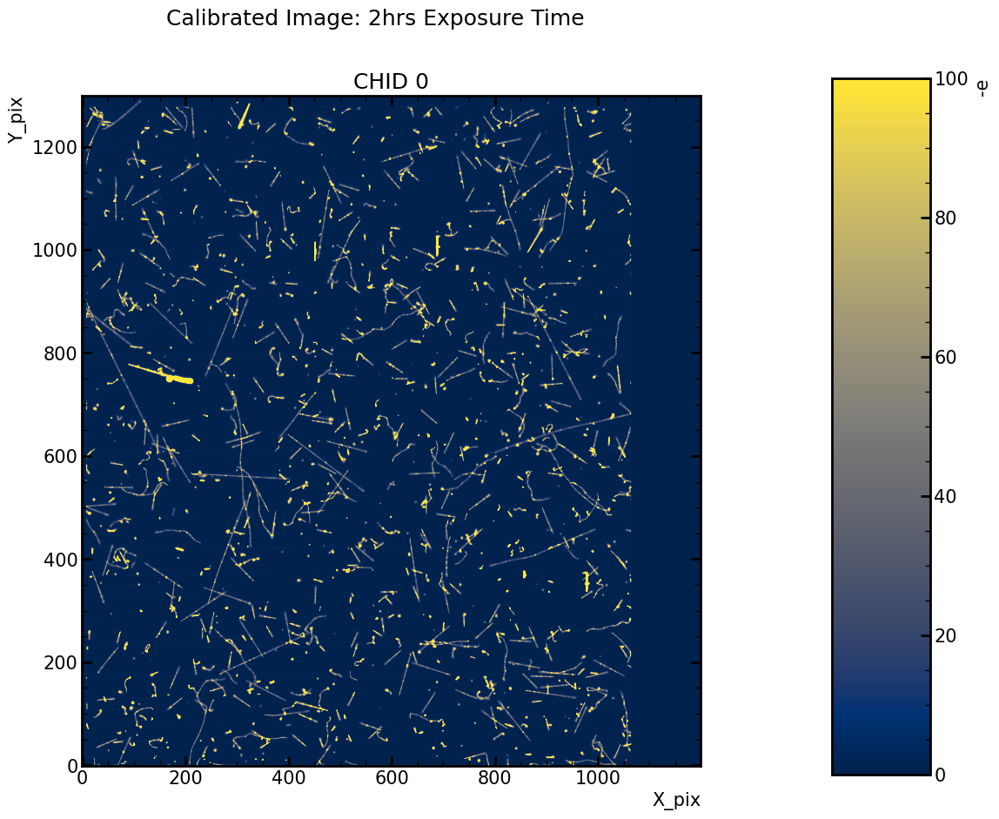

In [ ]:
data_pre = precal(hdu_list,extensions=4)
gain, gain_err, data= LocalCalib(data_pre,extensions=4)
fig=plt.figure(figsize=(15,10))
plt.subplot(1,1,1)

cmap = mpl.cm.cividis
plt.imshow(data[0],cmap=cmap,vmin=0,vmax=100)
plt.title('CHID '+str(0))
plt.ylabel('Y_pix')
plt.xlabel('X_pix')
print("CHID "+str(0)+' Gain:({:.2f} +- {:.2f})ADUs'.format(gain[0],gain_err[0]))
plt.suptitle('Calibrated Image: 2hrs Exposure Time')

cax = plt.axes([0.85, 0.1, 0.075, 0.8])
plt.colorbar(cax=cax)
plt.ylabel('-e')
#plt.savefig('IMAGES_POSCALIB.png', bbox_inches='tight', dpi=100)
    
plt.show()